In [1]:
# Imports library
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import transforms
from torch.utils.data import DataLoader, random_split, WeightedRandomSampler
from torchvision.datasets import ImageFolder
from sklearn.metrics import accuracy_score, classification_report, f1_score, precision_score, recall_score, confusion_matrix
import timm
import numpy as np
import matplotlib.pyplot as plt
from tqdm import tqdm
from collections import Counter
from PIL import Image
import time
from datetime import timedelta

C:\Users\LYSA\anaconda3\envs\pytorch2\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
# Dataset path
dataset_path = r"C:\Users\LYSA\Downloads\GEI_Output_nm_cl_bg"
test_nm_path = r"C:\Users\LYSA\Downloads\GEI_Output_test_nm"

In [3]:
# Transformations
train_transform = transforms.Compose([
    transforms.Grayscale(num_output_channels=3),
    transforms.Resize((256, 256)),  # Larger initial size
    transforms.RandomCrop(224),  # Random cropping
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomVerticalFlip(p=0.3),
    transforms.RandomRotation(15),
    transforms.RandomAffine(degrees=10, translate=(0.1, 0.1), scale=(0.9, 1.1)),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.1),
    transforms.RandomPerspective(distortion_scale=0.2, p=0.3),
    transforms.RandomErasing(p=0.3, scale=(0.02, 0.2), ratio=(0.3, 3.3)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

test_transform = transforms.Compose([
    transforms.Grayscale(num_output_channels=3),
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

In [4]:
# Load dataset
dataset = ImageFolder(root=dataset_path)
test_nm_dataset = ImageFolder(root=test_nm_path, transform=test_transform)
num_classes = len(dataset.classes)  

In [5]:
# Split training into train and validation
val_size = int(0.15 * len(dataset))
train_size = len(dataset) - val_size
train_dataset, val_dataset = random_split(
    dataset, [train_size, val_size],
    generator=torch.Generator().manual_seed(42)
)

In [6]:
# Class balancing
train_targets = [dataset.targets[i] for i in train_dataset.indices]
train_class_counts = Counter(train_targets)
max_count = max(train_class_counts.values())
train_class_weights = {k: max_count/v for k,v in train_class_counts.items()}
full_class_weights = torch.ones(num_classes, dtype=torch.float32)
for class_idx, weight in train_class_weights.items():
    full_class_weights[class_idx] = weight

train_sample_weights = [full_class_weights[t].item() for t in train_targets]
train_sampler = WeightedRandomSampler(
    weights=train_sample_weights,
    num_samples=len(train_sample_weights),
    replacement=True
)

In [7]:
# Apply transformations
train_dataset.dataset.transform = train_transform
val_dataset.dataset.transform = test_transform 

In [8]:
# Create DataLoaders with adjusted batch sizes
train_loader = DataLoader(
    train_dataset, batch_size=64,
    sampler=train_sampler, num_workers=8,
    pin_memory=True, persistent_workers=True
)
val_loader = DataLoader(
    val_dataset, batch_size=64,
    shuffle=False, num_workers=8,
    pin_memory=True, persistent_workers=True
)
test_nm_loader = DataLoader(
    test_nm_dataset, batch_size=64,
    shuffle=False, num_workers=8,
    pin_memory=True, persistent_workers=True
)

In [9]:
# Load pre-trained ViT & modify classification head
model = timm.create_model('vit_base_patch16_224', pretrained=True)

In [10]:
# Optimized classification head
model.head = nn.Sequential(
    nn.Linear(model.head.in_features, 1024),
    nn.BatchNorm1d(1024),
    nn.GELU(),
    nn.Dropout(0.3),
    nn.Linear(1024, 512),
    nn.BatchNorm1d(512),
    nn.GELU(),
    nn.Dropout(0.2),
    nn.Linear(512, num_classes)
)

In [11]:
# Move model to GPU
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model.to(device)

VisionTransformer(
  (patch_embed): PatchEmbed(
    (proj): Conv2d(3, 768, kernel_size=(16, 16), stride=(16, 16))
    (norm): Identity()
  )
  (pos_drop): Dropout(p=0.0, inplace=False)
  (patch_drop): Identity()
  (norm_pre): Identity()
  (blocks): Sequential(
    (0): Block(
      (norm1): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
      (attn): Attention(
        (qkv): Linear(in_features=768, out_features=2304, bias=True)
        (q_norm): Identity()
        (k_norm): Identity()
        (attn_drop): Dropout(p=0.0, inplace=False)
        (proj): Linear(in_features=768, out_features=768, bias=True)
        (proj_drop): Dropout(p=0.0, inplace=False)
      )
      (ls1): Identity()
      (drop_path1): Identity()
      (norm2): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
      (mlp): Mlp(
        (fc1): Linear(in_features=768, out_features=3072, bias=True)
        (act): GELU(approximate='none')
        (drop1): Dropout(p=0.0, inplace=False)
        (norm): Identity(

In [12]:
# Loss and optimizer with more regularization
class_weights_tensor = full_class_weights.to(device)
criterion = nn.CrossEntropyLoss(weight=class_weights_tensor)
optimizer = optim.AdamW(model.parameters(), lr=4e-5, weight_decay=1e-4)

In [13]:
# Cosine annealing with warm restarts
scheduler = optim.lr_scheduler.CosineAnnealingWarmRestarts(
    optimizer, 
    T_0=10,  # Number of iterations for first restart
    T_mult=1,  # Multiplication factor after restart
    eta_min=1e-6  # Minimum learning rate
)

In [14]:
# Training tracking
train_loss_history = []
train_acc_history = []
val_loss_history = []
val_acc_history = []
best_val_acc = 0.0
patience = 10 
counter = 0
scaler = torch.cuda.amp.GradScaler()
start_time = time.time()

# Training loop
epochs = 100  
for epoch in range(epochs):
    model.train()
    epoch_train_loss = 0.0
    correct = 0
    total = 0
    
    for images, labels in tqdm(train_loader, desc=f"Epoch {epoch+1}/{epochs}"):
        images, labels = images.to(device), labels.to(device)
        
        with torch.cuda.amp.autocast():
            outputs = model(images)
            loss = criterion(outputs, labels)
        
        optimizer.zero_grad()
        scaler.scale(loss).backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        scaler.step(optimizer)
        scaler.update()
        scheduler.step()
        
        epoch_train_loss += loss.item()
        _, predicted = torch.max(outputs, 1)
        correct += (predicted == labels).sum().item()
        total += labels.size(0)
    
    # Training metrics
    train_loss = epoch_train_loss / len(train_loader)
    train_acc = correct / total
    train_loss_history.append(train_loss)
    train_acc_history.append(train_acc)
    
    # Validation
    model.eval()
    val_loss = 0.0
    val_correct = 0
    val_total = 0
    
    with torch.no_grad():
        for images, labels in val_loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            loss = criterion(outputs, labels)
            val_loss += loss.item()
            _, predicted = torch.max(outputs, 1)
            val_correct += (predicted == labels).sum().item()
            val_total += labels.size(0)
    
    val_loss /= len(val_loader)
    val_acc = val_correct / val_total
    val_loss_history.append(val_loss)
    val_acc_history.append(val_acc)
    
    # Print epoch stats
    elapsed_time = time.time() - start_time
    avg_time_per_epoch = elapsed_time / (epoch + 1)
    remaining_time = avg_time_per_epoch * (epochs - epoch - 1)
    
    print(f"\nEpoch {epoch+1} Results:")
    print(f"Train Loss: {train_loss:.4f} | Train Acc: {train_acc*100:.2f}%")
    print(f"Val Loss: {val_loss:.4f} | Val Acc: {val_acc*100:.2f}%")
    print(f"Current LR: {scheduler.get_last_lr()[0]:.2e}")
    print(f"Elapsed: {str(timedelta(seconds=int(elapsed_time)))}")
    print(f"Remaining: {str(timedelta(seconds=int(remaining_time)))}")
    
    # Early stopping
    if val_acc > best_val_acc:
        best_val_acc = val_acc
        counter = 0
        torch.save({
            'epoch': epoch,
            'model_state_dict': model.state_dict(),
            'optimizer_state_dict': optimizer.state_dict(),
            'val_acc': val_acc,
            'val_loss': val_loss,
        }, 'best_model_allNM.pth')
    else:
        counter += 1
        if counter >= patience:
            print(f"\nEarly stopping triggered at epoch {epoch+1}")
            break

# Training complete
total_time = time.time() - start_time
print(f"\nTraining completed in: {str(timedelta(seconds=int(total_time)))}")

C:\Users\LYSA\AppData\Local\Temp\ipykernel_2000\3608304951.py:9: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler()
C:\Users\LYSA\AppData\Local\Temp\ipykernel_2000\3608304951.py:23: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast():
Epoch 1/100: 100%|█████████████████████████████████████████████████████████████████████| 10/10 [03:24<00:00, 20.43s/it]



Epoch 1 Results:
Train Loss: 4.8594 | Train Acc: 1.74%
Val Loss: 4.8000 | Val Acc: 0.90%
Current LR: 4.00e-05
Elapsed: 0:04:17
Remaining: 7:05:33


Epoch 2/100: 100%|█████████████████████████████████████████████████████████████████████| 10/10 [03:20<00:00, 20.08s/it]



Epoch 2 Results:
Train Loss: 4.6856 | Train Acc: 2.37%
Val Loss: 4.7191 | Val Acc: 5.41%
Current LR: 4.00e-05
Elapsed: 0:08:23
Remaining: 6:51:12


Epoch 3/100: 100%|█████████████████████████████████████████████████████████████████████| 10/10 [03:18<00:00, 19.81s/it]


...


Epoch 54 Results:
Train Loss: 0.8266 | Train Acc: 100.00%
Val Loss: 2.3040 | Val Acc: 86.49%
Current LR: 4.00e-05
Elapsed: 3:32:44
Remaining: 3:01:13


Epoch 55/100: 100%|████████████████████████████████████████████████████████████████████| 10/10 [03:12<00:00, 19.26s/it]



Epoch 55 Results:
Train Loss: 0.8170 | Train Acc: 100.00%
Val Loss: 2.2799 | Val Acc: 85.59%
Current LR: 4.00e-05
Elapsed: 3:36:33
Remaining: 2:57:10


Epoch 56/100: 100%|████████████████████████████████████████████████████████████████████| 10/10 [03:12<00:00, 19.26s/it]



Epoch 56 Results:
Train Loss: 0.7584 | Train Acc: 100.00%
Val Loss: 2.1963 | Val Acc: 86.49%
Current LR: 4.00e-05
Elapsed: 3:40:22
Remaining: 2:53:08

Early stopping triggered at epoch 56

Training completed in: 3:40:22


In [15]:
# Load best model
checkpoint = torch.load('best_model_allNM.pth')
model.load_state_dict(checkpoint['model_state_dict'])

<All keys matched successfully>

In [16]:
# Final evaluation on test set
model.eval()
y_true, y_pred = [], []
test_loss = 0.0

with torch.no_grad():
    for images, labels in tqdm(test_nm_loader, desc="Testing"):
        images, labels = images.to(device), labels.to(device)
        outputs = model(images)
        loss = criterion(outputs, labels)
        test_loss += loss.item()
        _, predicted = torch.max(outputs, 1)
        y_true.extend(labels.cpu().numpy())
        y_pred.extend(predicted.cpu().numpy())

Testing: 100%|███████████████████████████████████████████████████████████████████████████| 4/4 [02:15<00:00, 33.99s/it]


In [17]:
# Calculate metrics
test_loss /= len(test_nm_loader)
accuracy = accuracy_score(y_true, y_pred)
f1 = f1_score(y_true, y_pred, average='weighted')
precision = precision_score(y_true, y_pred, average='weighted')
recall = recall_score(y_true, y_pred, average='weighted')

print("\nFinal Test Results for Normal Walking:")
print(f"Test Loss: {test_loss:.4f}")
print(f"Accuracy: {accuracy*100:.2f}%")
print(f"F1 Score: {f1*100:.2f}%")
print(f"Precision: {precision*100:.2f}%")
print(f"Recall: {recall*100:.2f}%")


Final Test Results for Normal Walking:
Test Loss: 1.8575
Accuracy: 97.18%
F1 Score: 97.02%
Precision: 97.98%
Recall: 97.18%


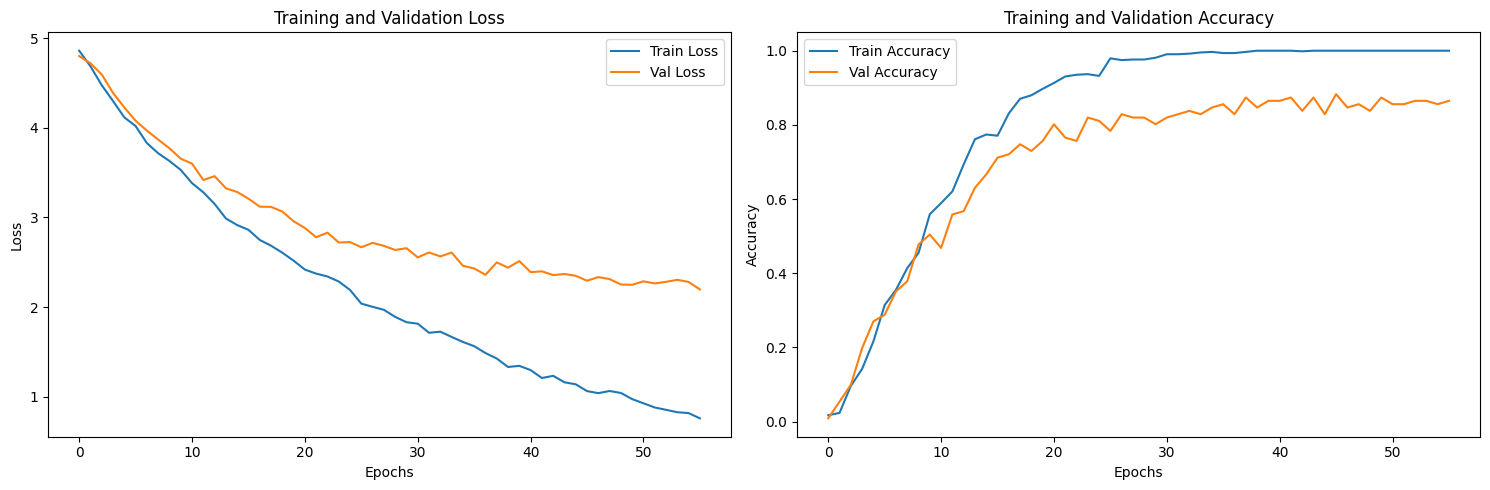

In [18]:
# Plot training and validation metrics
plt.figure(figsize=(15, 5))

# Loss plot
plt.subplot(1, 2, 1)
plt.plot(train_loss_history, label='Train Loss')
plt.plot(val_loss_history, label='Val Loss')
plt.title('Training and Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()

# Accuracy plot
plt.subplot(1, 2, 2)
plt.plot(train_acc_history, label='Train Accuracy')
plt.plot(val_acc_history, label='Val Accuracy')
plt.title('Training and Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()

plt.tight_layout()
plt.show()

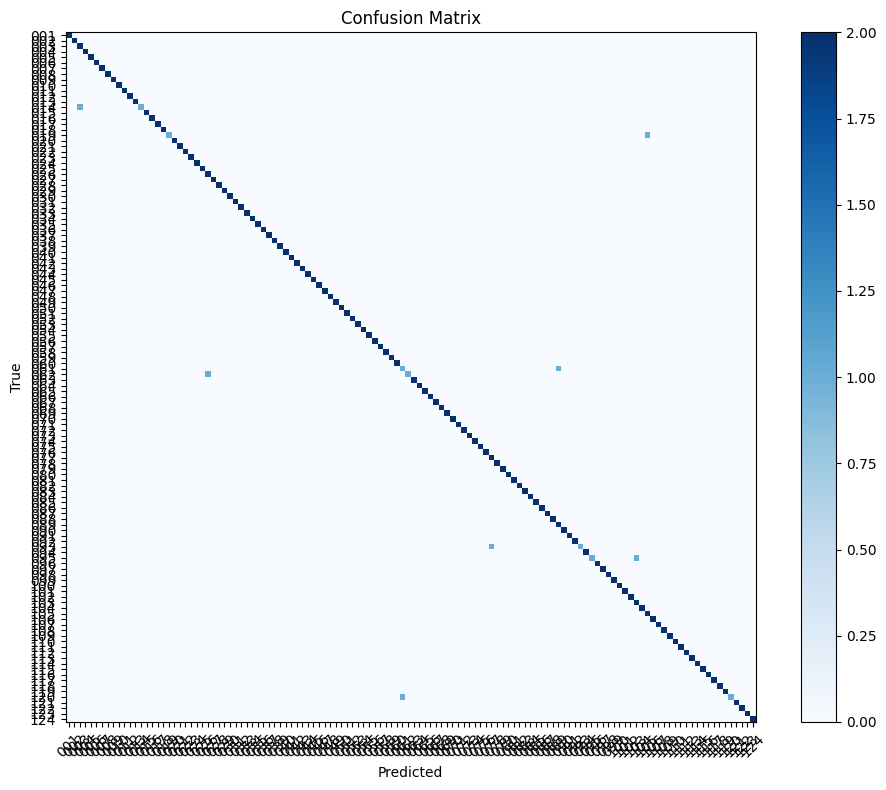

In [19]:
# Confusion Matrix
cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(10, 8))
plt.imshow(cm, cmap=plt.cm.Blues)
plt.title("Confusion Matrix")
plt.colorbar()
plt.xlabel("Predicted")
plt.ylabel("True")
tick_marks = np.arange(len(dataset.classes))
plt.xticks(tick_marks, dataset.classes, rotation=45)
plt.yticks(tick_marks, dataset.classes)
plt.tight_layout()
plt.show()

In [20]:
#Classification Report
print("Classification Report:")
print(classification_report(y_true, y_pred, labels=np.unique(y_true)))

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00         2
           1       1.00      1.00      1.00         2
           2       0.67      1.00      0.80         2
           3       1.00      1.00      1.00         2
           4       1.00      1.00      1.00         2
           5       1.00      1.00      1.00         2
           6       1.00      1.00      1.00         2
           7       1.00      1.00      1.00         2
           8       1.00      1.00      1.00         2
           9       1.00      1.00      1.00         2
          10       1.00      1.00      1.00         2
          11       1.00      1.00      1.00         2
          12       1.00      1.00      1.00         2
          13       1.00      0.50      0.67         2
          14       1.00      1.00      1.00         2
          15       1.00      1.00      1.00         2
          16       1.00      1.00      1.00         2
    